In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from eda_manager.chart.custom.chart_group.timeseries import split_datetime
from eda_manager.chart.chart_helper import (update_chart_with_common_option,
                                            common_option,
                                            save_chart_to_bytes,
                                            close_pyplot, DBDREAM)

In [2]:
from eda_manager.chart.custom.chart_group.timeseries import dist_datetime

In [3]:
def display_img_bytes(img_bytes):
    import base64
    from IPython.display import Image, display

    image_data = base64.b64decode(img_bytes)
    display(Image(data=image_data))

In [4]:
project_dir = r"C:\Users\10007166\insightmaker_project\Fabout CTPL 분석"
dt = "Fab In"

In [9]:
img = dist_datetime(project_dir, dt,
            common_option(
                chart_nm="auto", chart_nm_font_size=10,
                axis_font_size="auto",
                x_axis_rotate="auto"                           
            ))

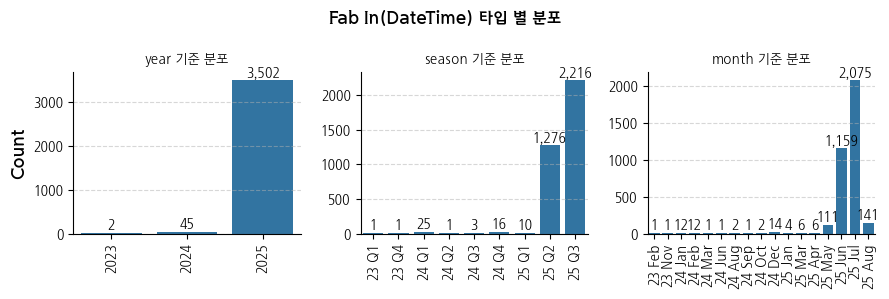

In [10]:
display_img_bytes(img)

In [4]:
img = None
data_path = os.path.join(project_dir, 'data.pkl')
df = pd.read_pickle(data_path)
dt_cols = ['year','season','month','week','day','hour','minute','second']
df_dt = pd.DataFrame(df.sort_values(dt, ascending=True).reset_index(drop=True))
df_dt[dt_cols] = df_dt.apply(
    lambda x: split_datetime(x[dt]), axis=1, result_type='expand')
draw_cols = [col for col in dt_cols
                if (len(df_dt[col].unique())<=30 and len(df_dt[col].unique())>1)]
df_dt = df_dt[draw_cols]

df_dt_type = None
for col in df_dt.columns:
    temp = pd.DataFrame(df_dt[col])
    temp = temp.rename(columns={col: "dt_value"})
    temp["dt_type"] = col
    if df_dt_type is None:
        df_dt_type = temp
    else:
        df_dt_type = pd.concat([df_dt_type, temp], axis=0)
df_dt_type["dt_value"] = df_dt_type["dt_value"].astype(str)

def countplot_limited_x(data, color):
    label_fmt = lambda v: f"{v:,.0f}"
    order = data["dt_value"].unique()
    ax = sns.countplot(data=data, x="dt_value", order=order, color=color)
    for container in ax.containers:
        labels = [label_fmt(v) if v!=0 else '' for v in container.datavalues]
        ax.bar_label(container, label_type='edge', labels=labels)
    ax.set(xlabel=None)
    ax.tick_params(axis="x", rotation=90)
    ax.grid(True, axis="y", linestyle='--', alpha=.5)

g = sns.FacetGrid(df_dt_type, col="dt_type", sharex=False, sharey=False, col_wrap=3)
g.map_dataframe(countplot_limited_x)
g.set_titles(col_template="{col_name} 기준 분포")
g.fig.suptitle("DateTime 타입 별 분포")
g.tight_layout()
img = save_chart_to_bytes(g)

In [50]:
%matplotlib inline

In [5]:
df_dt_type = None
for col in df_dt.columns:
    temp = pd.DataFrame(df_dt[col])
    temp = temp.rename(columns={col: "dt_value"})
    temp["dt_type"] = col
    if df_dt_type is None:
        df_dt_type = temp
    else:
        df_dt_type = pd.concat([df_dt_type, temp], axis=0)
df_dt_type["dt_value"] = df_dt_type["dt_value"].astype(str)

In [12]:
def countplot_limited_x(data, color):
    label_fmt = lambda v: f"{v:,.0f}"
    order = data["dt_value"].unique()
    ax = sns.countplot(data=data, x="dt_value", order=order, color=color)
    for container in ax.containers:
        labels = [label_fmt(v) if v!=0 else '' for v in container.datavalues]
        ax.bar_label(container, label_type='edge', labels=labels)
    ax.set(xlabel=None)
    ax.tick_params(axis="x", rotation=90)
    ax.grid(True, axis="y", linestyle='--', alpha=.5)

g = sns.FacetGrid(df_dt_type, col="dt_type", sharex=False, sharey=False, col_wrap=3)
g.map_dataframe(countplot_limited_x)
g.set_titles(col_template="{col_name} 기준 분포")
g.fig.suptitle("DateTime 타입 별 분포")
g.tight_layout()
img = save_chart_to_bytes(g)

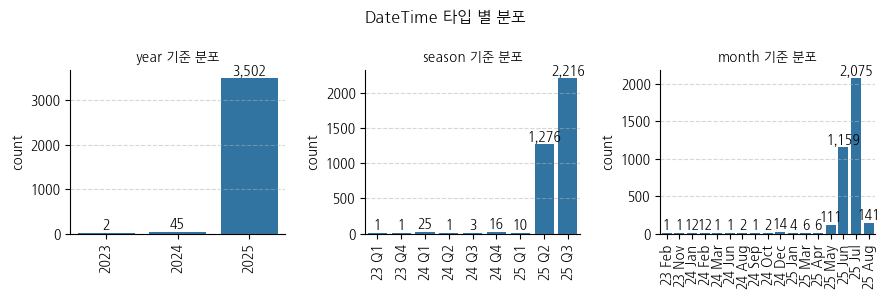

In [13]:
display_img_bytes(img)